In [1]:
import zipfile
import random
import warnings
import itertools

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostRegressor
from scipy.constants import inch

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")

In [2]:
train = pd.read_csv("train.csv")
X_test = pd.read_csv("test.csv")

display(
    train.info(),
    train.columns,
    X_test.info(),
    X_test.columns
)

<class 'pandas.DataFrame'>
RangeIndex: 668665 entries, 0 to 668664
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           668665 non-null  int64  
 1   Age                          668665 non-null  int64  
 2   Annual_Income_USD            668665 non-null  float64
 3   Daily_Commute_km             668665 non-null  float64
 4   Number_of_Cars_Owned         668665 non-null  int64  
 5   Charging_Stations_Near_Home  668665 non-null  int64  
 6   Charging_Stations_Near_Work  668665 non-null  int64  
 7   Environmental_Concern_Level  668665 non-null  float64
 8   Gender                       668665 non-null  str    
 9   City_Type                    668665 non-null  str    
 10  Current_Car_Type             668665 non-null  str    
 11  Home_Charging_Possible       668665 non-null  str    
 12  Subsidy_Available            668665 non-null  str    
 13  Range_Anxi

None

Index(['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km',
       'Number_of_Cars_Owned', 'Charging_Stations_Near_Home',
       'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender',
       'City_Type', 'Current_Car_Type', 'Home_Charging_Possible',
       'Subsidy_Available', 'Range_Anxiety_Level', 'Will_Buy_EV'],
      dtype='str')

None

Index(['id', 'Age', 'Annual_Income_USD', 'Daily_Commute_km',
       'Number_of_Cars_Owned', 'Charging_Stations_Near_Home',
       'Charging_Stations_Near_Work', 'Environmental_Concern_Level', 'Gender',
       'City_Type', 'Current_Car_Type', 'Home_Charging_Possible',
       'Subsidy_Available', 'Range_Anxiety_Level'],
      dtype='str')

In [3]:
train.nunique()

id                             668665
Age                                45
Annual_Income_USD               13214
Daily_Commute_km                  805
Number_of_Cars_Owned                4
Charging_Stations_Near_Home        15
Charging_Stations_Near_Work        20
Environmental_Concern_Level         5
Gender                              3
City_Type                           3
Current_Car_Type                    4
Home_Charging_Possible              2
Subsidy_Available                   2
Range_Anxiety_Level                 3
Will_Buy_EV                         2
dtype: int64

In [4]:
train.shape

(668665, 15)

In [5]:
X_test.nunique()

id                             286571
Age                                45
Annual_Income_USD               10526
Daily_Commute_km                  781
Number_of_Cars_Owned                4
Charging_Stations_Near_Home        15
Charging_Stations_Near_Work        20
Environmental_Concern_Level         5
Gender                              3
City_Type                           3
Current_Car_Type                    4
Home_Charging_Possible              2
Subsidy_Available                   2
Range_Anxiety_Level                 3
dtype: int64

In [6]:
train.drop(columns=['id']).describe()

,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000,668665.000000
mean,47.039171,84769.266989,32.158298,1.712626,4.960408,7.176314,2.935477
std,12.875448,28648.029042,18.730474,0.729275,3.926843,5.186627,1.429119
min,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,36.000000,67376.000000,17.200000,1.000000,2.000000,3.000000,2.000000
50%,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,58.000000,102753.000000,47.400000,2.000000,7.000000,10.000000,4.000000
max,69.000000,188549.000000,98.700000,4.000000,14.000000,19.000000,5.000000


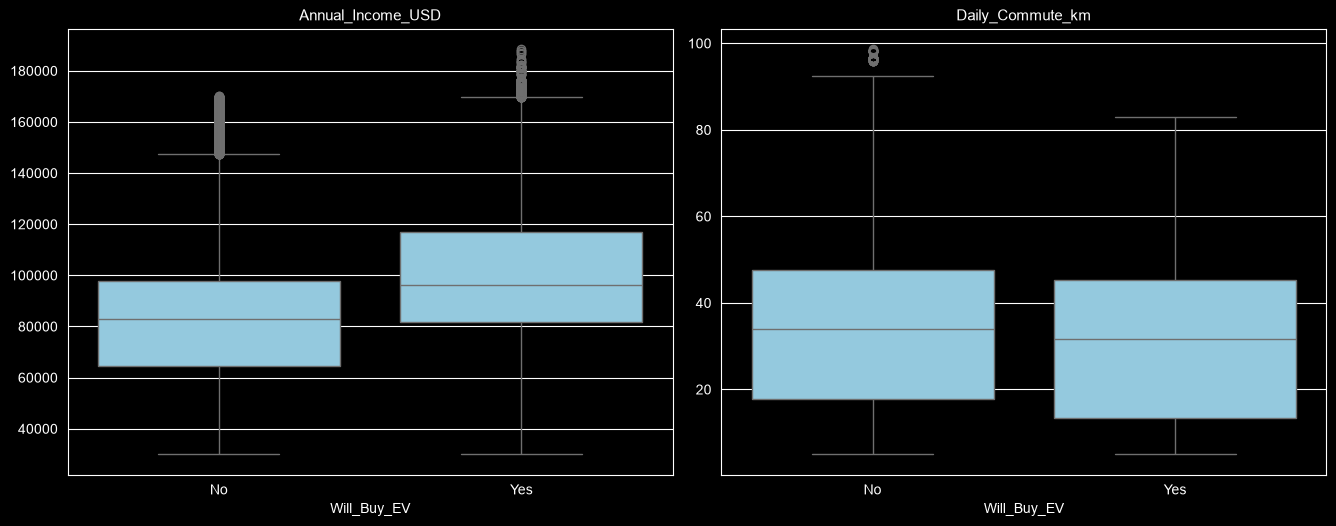

In [7]:
plt.figure(figsize=(20,15))

for i, col in enumerate(['Annual_Income_USD','Daily_Commute_km'], 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x='Will_Buy_EV',y=col, data=train, color='skyblue')
    plt.title(col, fontsize=11)
    plt.ylabel('')

plt.tight_layout()
plt.show()

In [8]:
def quart_bound(serie: pd.Series):
    q1 = np.percentile(serie, 25)
    q3 = np.percentile(serie, 75)

    iqr = q3-q1

    lower_boundary = q1 - 1.5 * iqr
    upper_boundary = q3 + 1.5 * iqr

    # 4. Находим реальные концы усов (в пределах порогов)
    whisker_low = serie[serie >= lower_boundary].min()
    whisker_high = serie[serie <= upper_boundary].max()

    print(f"Нижний порог (конец уса): {whisker_low}")
    print(f"Верхний порог (конец уса): {whisker_high}")

    return whisker_high

USD_high = quart_bound(train["Annual_Income_USD"])
KM_high = quart_bound(train["Daily_Commute_km"])

Нижний порог (конец уса): 30000.0
Верхний порог (конец уса): 155798.0
Нижний порог (конец уса): 5.0
Верхний порог (конец уса): 92.5


In [9]:
train = train[train["Annual_Income_USD"] < USD_high]
train = train[train["Daily_Commute_km"] < KM_high]

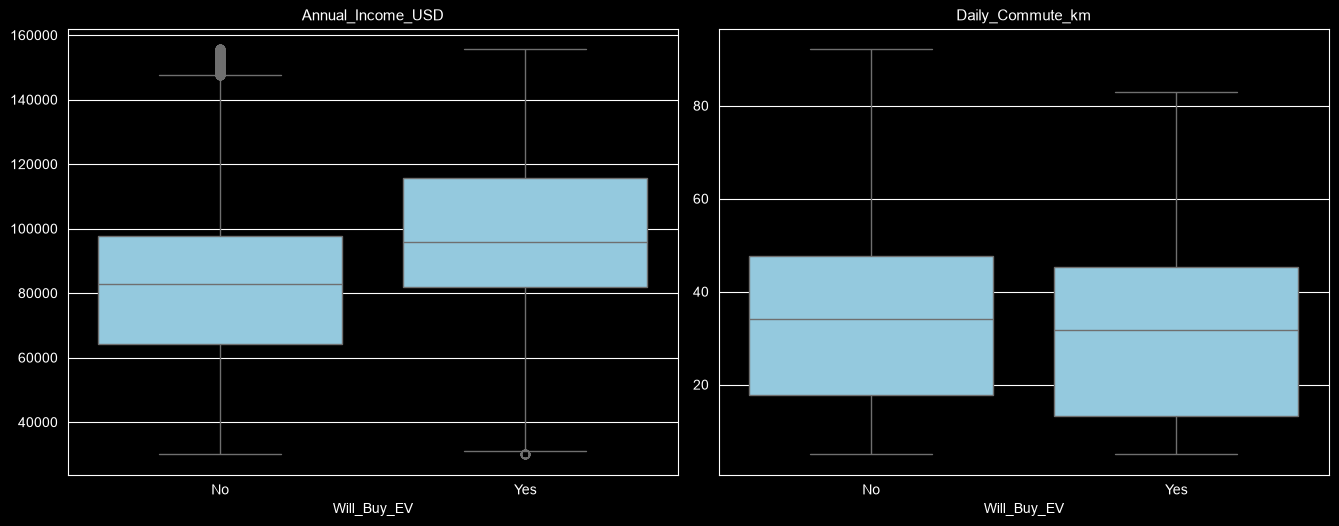

In [10]:
plt.figure(figsize=(20,15))

for i, col in enumerate(['Annual_Income_USD','Daily_Commute_km'], 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x='Will_Buy_EV',y=col, data=train, color='skyblue')
    plt.title(col, fontsize=11)
    plt.ylabel('')

plt.tight_layout()
plt.show()

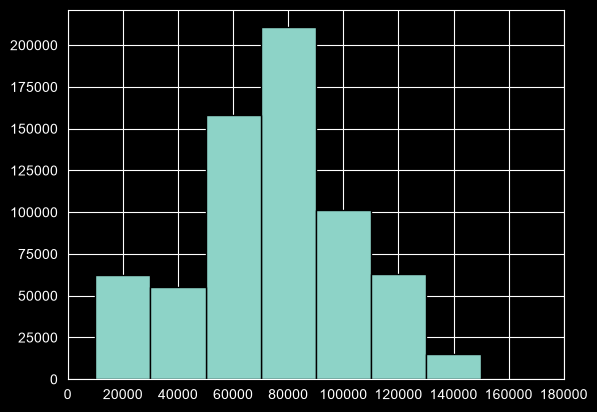

In [11]:
from collections import Counter

histogram = Counter(min(grade//20000 * 20000,180000) for grade in train["Annual_Income_USD"])
plt.bar([x+5 for x in histogram.keys()],
        histogram.values(),
        20000,
        edgecolor=(0,0,0))
plt.xticks([20000 * i for i in range(10)])
plt.show()

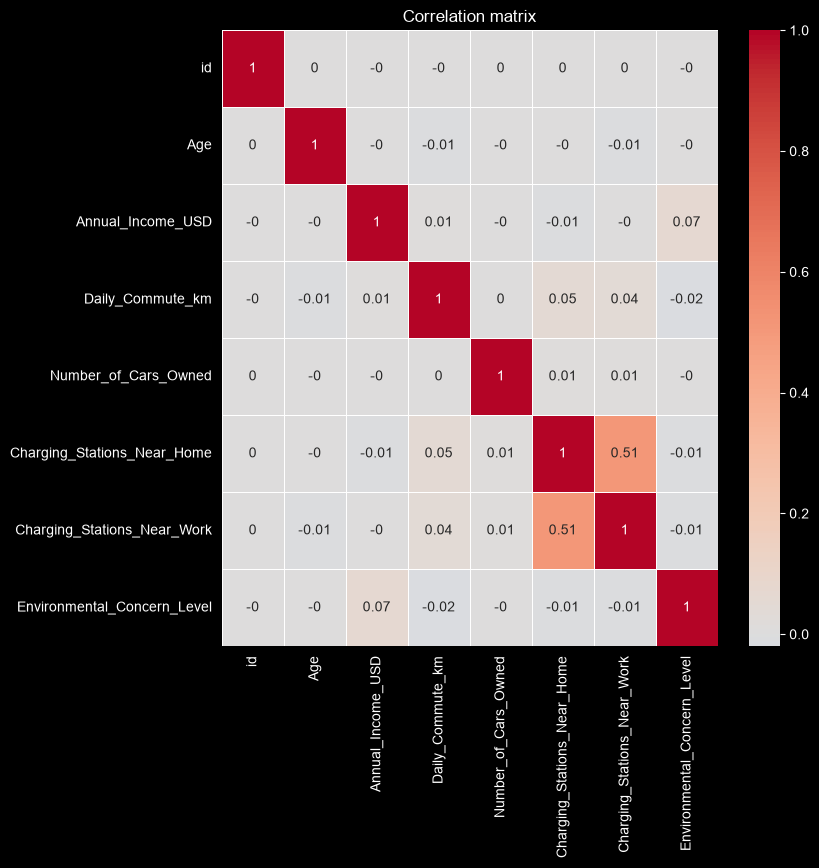

In [12]:
plt.figure(figsize=(8,8))
corr_matrix = train.corr(numeric_only=True, method='pearson')
corr_matrix = np.round(corr_matrix, 2)
sns.heatmap(
    corr_matrix,
    annot=True,
    linewidths=.5,
    cmap="coolwarm",
    center=0
)

plt.title('Correlation matrix')
plt.show()

### Кошькабуст

In [13]:
X_train = train.drop(columns=['Will_Buy_EV'])
y_train = train['Will_Buy_EV']
y_train[y_train == 'Yes'] = '1'
y_train[y_train == 'No'] = '0'
y_train = y_train.astype(float)

In [14]:
reg_features = ['Age',
                'Annual_Income_USD',
                'Daily_Commute_km',
                'Number_of_Cars_Owned',
                'Charging_Stations_Near_Home',
                'Charging_Stations_Near_Work',
                'Environmental_Concern_Level']

cat_features = ['Gender',
                'City_Type',
                'Current_Car_Type',
                'Home_Charging_Possible',
                'Subsidy_Available',
                'Range_Anxiety_Level']

cat = CatBoostRegressor(iterations=1000, learning_rate=0.1, l2_leaf_reg=1, depth=7, random_seed=42, verbose=False)
cat.fit(X_train[reg_features + cat_features], y_train, cat_features=cat_features)

y_test = cat.predict(X_test[reg_features + cat_features])
len(y_test)

286571

In [15]:
submission = pd.DataFrame({
    "id":X_test["id"],
    "Will_Buy_EV":y_test
})
submission.shape

(286571, 2)

In [16]:
submission.to_csv("submission.csv", index=False)